Here we(I and Gemini) calculate the formula for the backpropagation of batch normalization. For batch normalization, each channel is independent, so the formula for each column can be used for other columns without any trouble. In other words, batch Normalization operates independently on each feature channel, so we can simplify our math by looking at just a single feature (one column). Let’s assume our batch has size $N$ (represented by `bs` in your code), and the inputs for this feature across the batch are $X_1, X_2, \dots, X_N$.

---

## 1. The Mathematical Proof

Here is the forward pass math for a single feature:

1. **Mean:** $\mu = \frac{1}{N} \sum_{k=1}^N X_k$
2. **Variance:** $\sigma^2 = \frac{1}{N} \sum_{k=1}^N (X_k - \mu)^2$
3. **Standard Deviation:** $\text{std} = \sqrt{\sigma^2 + \epsilon}$
4. **Normalized Output:** $\hat{X}_i = \frac{X_i - \mu}{\text{std}}$

We are given the incoming gradient $\delta_i = \frac{\partial L}{\partial \hat{X}_i}$ from the layer above. We want to find $\frac{\partial L}{\partial X_i}$.

Because $X_i$ contributes to the mean $\mu$ and variance $\sigma^2$, it affects **every single** $\hat{X}_k$ in the batch. Therefore, the total derivative requires a summation over the whole batch:

$$\frac{\partial L}{\partial X_i} = \sum_{k=1}^N \frac{\partial L}{\partial \hat{X}_k} \frac{\partial \hat{X}_k}{\partial X_i} = \sum_{k=1}^N \delta_k \frac{\partial \hat{X}_k}{\partial X_i}$$

### Step A: Compute $\frac{\partial \hat{X}_k}{\partial X_i}$

Using the quotient rule or product rule on $\hat{X}_k = (X_k - \mu) \cdot \text{std}^{-1}$:

$$\frac{\partial \hat{X}_k}{\partial X_i} = \frac{\partial (X_k - \mu)}{\partial X_i} \cdot \text{std}^{-1} + (X_k - \mu) \cdot \frac{\partial (\text{std}^{-1})}{\partial X_i}$$

Let’s break down the two inner derivatives:

1. **The first part:** 
$$\frac{\partial (X_k - \mu)}{\partial X_i} = \mathbb{I}(k = i) - \frac{1}{N}$$



*(Where $\mathbb{I}(k=i)$ is $1$ if $k=i$, and $0$ otherwise, because $\frac{\partial X_k}{\partial X_i} = 1$ only when $k=i$.)*
2. **The second part:** Using the chain rule on the variance:

$$\frac{\partial (\text{std}^{-1})}{\partial X_i} = -\frac{1}{\text{std}^2} \cdot \frac{1}{2\text{std}} \cdot \frac{\partial \sigma^2}{\partial X_i} = -\frac{1}{2\text{std}^3} \cdot \frac{\partial \sigma^2}{\partial X_i}$$



Now find $\frac{\partial \sigma^2}{\partial X_i}$:

$$\frac{\partial \sigma^2}{\partial X_i} = \frac{\partial \frac{1}{N}[(X_1 - \mu)^2+(X_2 - \mu)^2+ ...]}{\partial X_i} = \frac{2}{N} \sum_{m=1}^N (X_m - \mu) \cdot \left( \mathbb{I}(m=i) - \frac{1}{N} \right) = \frac{2}{N}(X_i - \mu) - \frac{2}{N^2}\sum_{m=1}^N(X_m - \mu)$$



Because the sum of deviations from the mean $\sum (X_m - \mu)$ is always $0$, the second term vanishes:

$$\frac{\partial \sigma^2}{\partial X_i} = \frac{2}{N}(X_i - \mu)$$



Plugging this back into our standard deviation derivative:

$$\frac{\partial (\text{std}^{-1})}{\partial X_i} = -\frac{1}{2\text{std}^3} \cdot \frac{2}{N}(X_i - \mu) = -\frac{1}{N \cdot \text{std}^2} \cdot \left(\frac{X_i - \mu}{\text{std}}\right) = -\frac{1}{N \cdot \text{std}^2} \hat{X}_i$$



### Step B: Substitute back into $\frac{\partial \hat{X}_k}{\partial X_i}$

$$\frac{\partial \hat{X}_k}{\partial X_i} = \left( \mathbb{I}(k=i) - \frac{1}{N} \right) \text{std}^{-1} + (X_k - \mu) \left( -\frac{1}{N \cdot \text{std}^2} \hat{X}_i \right)$$

Factor out $\frac{1}{\text{std}}$:


$$\frac{\partial \hat{X}_k}{\partial X_i} = \frac{1}{\text{std}} \left[ \mathbb{I}(k=i) - \frac{1}{N} - \frac{1}{N}\hat{X}_k\hat{X}_i \right]$$
$$\frac{\partial \gamma \hat{X}_k}{\partial X_i} = \frac{\gamma}{\text{std}} \left[ \mathbb{I}(k=i) - \frac{1}{N} - \frac{1}{N}\hat{X}_k\hat{X}_i \right]$$

### Step C: Calculate the final total gradient $\frac{\partial L}{\partial X_i}$

Now distribute the summation $\sum_{k=1}^N \delta_k$:

$$\frac{\partial L}{\partial X_i} = \sum_{k=1}^N \delta_k \cdot \frac{1}{\text{std}} \left[ \mathbb{I}(k=i) - \frac{1}{N} - \frac{1}{N}\hat{X}_k\hat{X}_i \right]$$

$$\frac{\partial L}{\partial X_i} = \frac{1}{\text{std}} \left[ \sum_{k=1}^N \delta_k\mathbb{I}(k=i) - \frac{1}{N}\sum_{k=1}^N \delta_k - \frac{1}{N}\hat{X}_i\sum_{k=1}^N \delta_k\hat{X}_k \right]$$

$$\frac{\partial L}{\partial X_i} = \frac{1}{\text{std}} \left[ \delta_i - \frac{1}{N}\sum_{k=1}^N \delta_k - \frac{1}{N}\hat{X}_i\sum_{k=1}^N \delta_k\hat{X}_k \right]$$

To get it exactly into the form used in your Python code, factor out $\frac{1}{N}$:

$$\frac{\partial L}{\partial X_i} = \frac{1}{N \cdot \text{std}} \left[ N \cdot \delta_i - \sum_{k=1}^N \delta_k - \hat{X}_i\sum_{k=1}^N \delta_k\hat{X}_k \right]$$
$$\frac{\partial L}{\partial X_i} = \frac{\gamma}{N \cdot \text{std}} \left[ N \cdot \delta_i - \sum_{k=1}^N \delta_k - \hat{X}_i\sum_{k=1}^N \delta_k\hat{X}_k \right]$$
---

## 2. Why is the code structured this way?

Instead of calculating intermediate gradients step-by-step (e.g., computing $\frac{\partial L}{\partial \sigma^2}$ then $\frac{\partial L}{\partial \mu}$ separately), this block combines everything into a single mathematical statement.

```python
dX = (1.0 / (bs * self.std)) * (
    bs * delta 
    - np.sum(delta, axis=0, keepdims=True) 
    - self.X_hat * np.sum(delta * self.X_hat, axis=0, keepdims=True)
)

```

There are three major reasons for this layout:

* **Computation Speed (Vectorization):** In Python, loops are slow. By reducing the entire chain rule down to a single simplified formula, NumPy can execute the math using highly optimized, element-wise matrix wrappers.
* **Memory Efficiency:** A step-by-step backpropagation creates multiple intermediate arrays of shape `(batch_size, features)` to store intermediate gradients. This compressed formula keeps memory overhead extremely low by relying only on column reductions (`np.sum(..., axis=0)`).
* **Numerical Stability:** Simplifying the mathematical equations analytically on paper beforehand cancels out terms that could otherwise cause floating-point errors (like dividing by values close to zero multiple times during sequential steps).

![Weixin Image_20260601094510_166_14.jpg](<attachment:Weixin Image_20260601094510_166_14.jpg>)
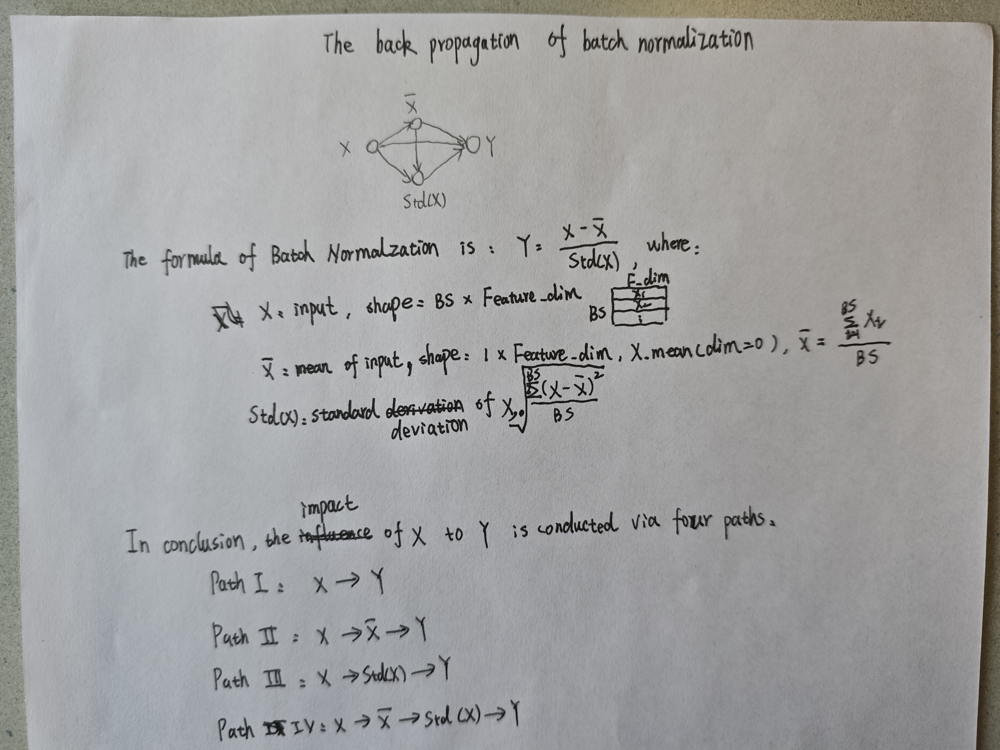

![Weixin Image_20260601095837_167_14.jpg](<attachment:Weixin Image_20260601095837_167_14.jpg>)
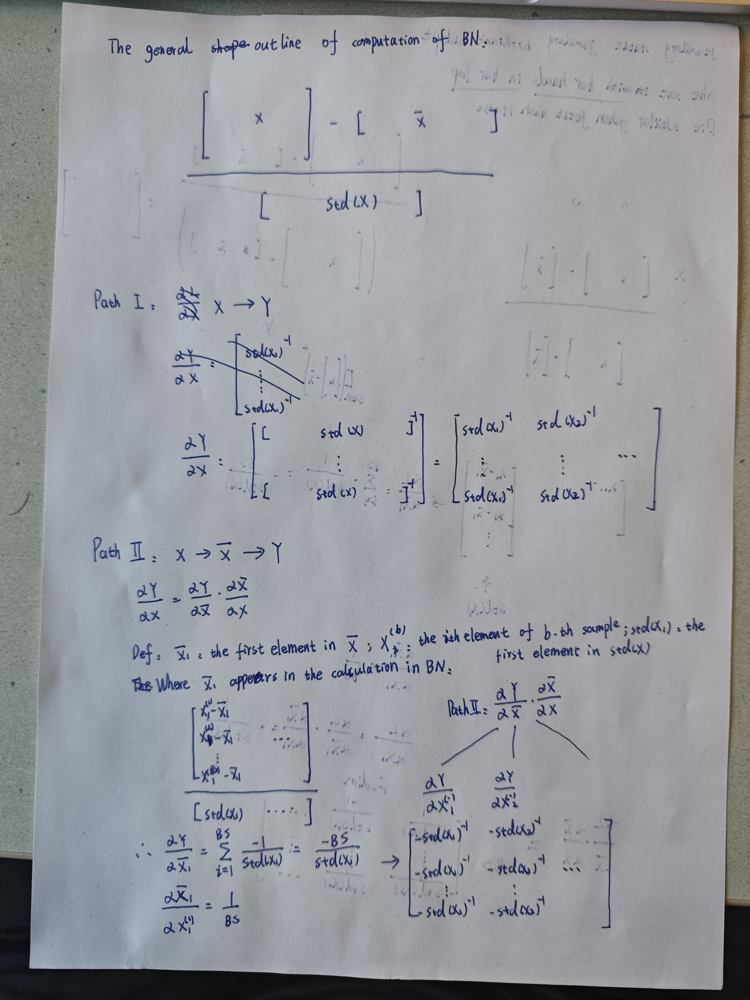

![Weixin Image_20260604134346_180_14.jpg](<attachment:Weixin Image_20260604134346_180_14.jpg>)
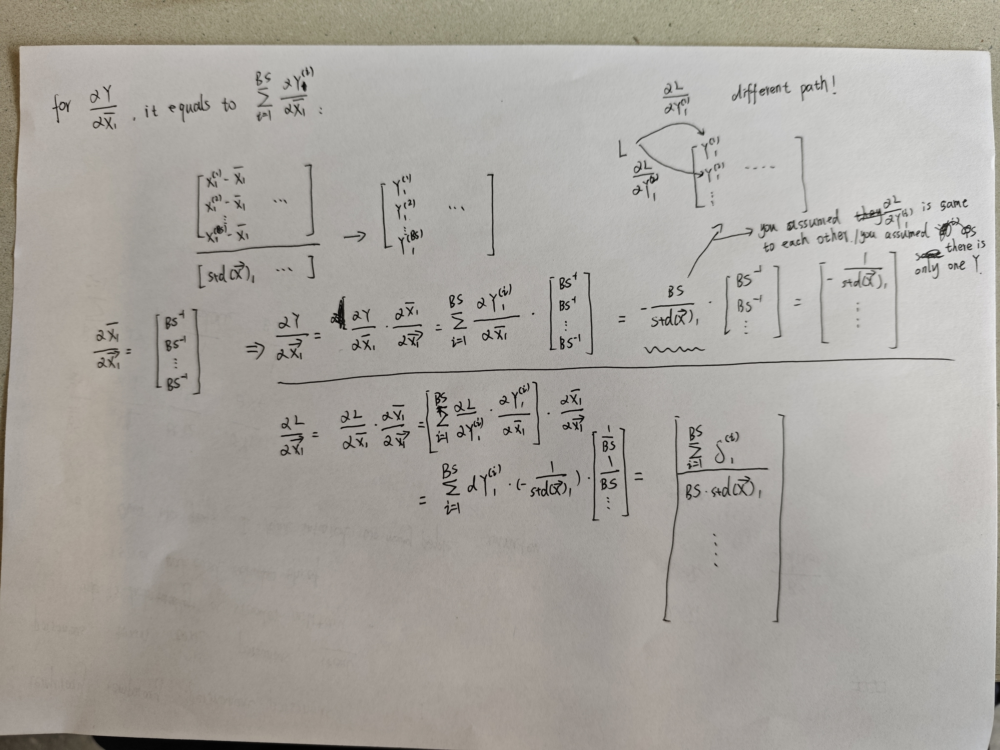

![Weixin Image_20260605143551_182_14.jpg](<attachment:Weixin Image_20260605143551_182_14.jpg>)
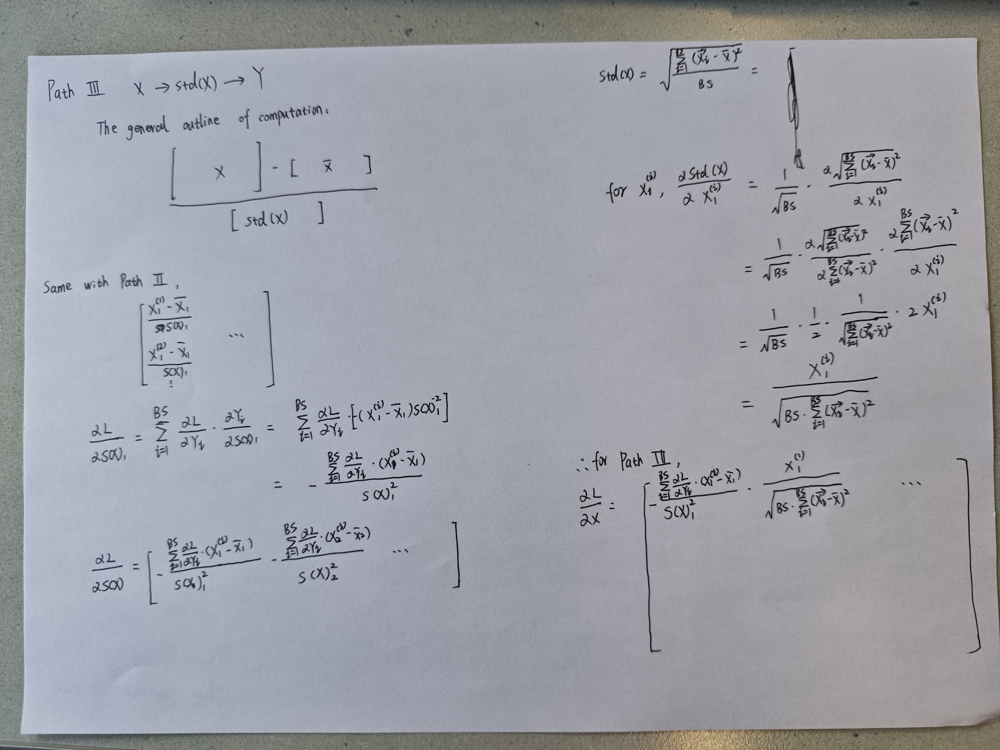

![backpropagation of batchnormaliyation-path iv.jpeg](<attachment:backpropagation of batchnormaliyation-path iv.jpeg>)
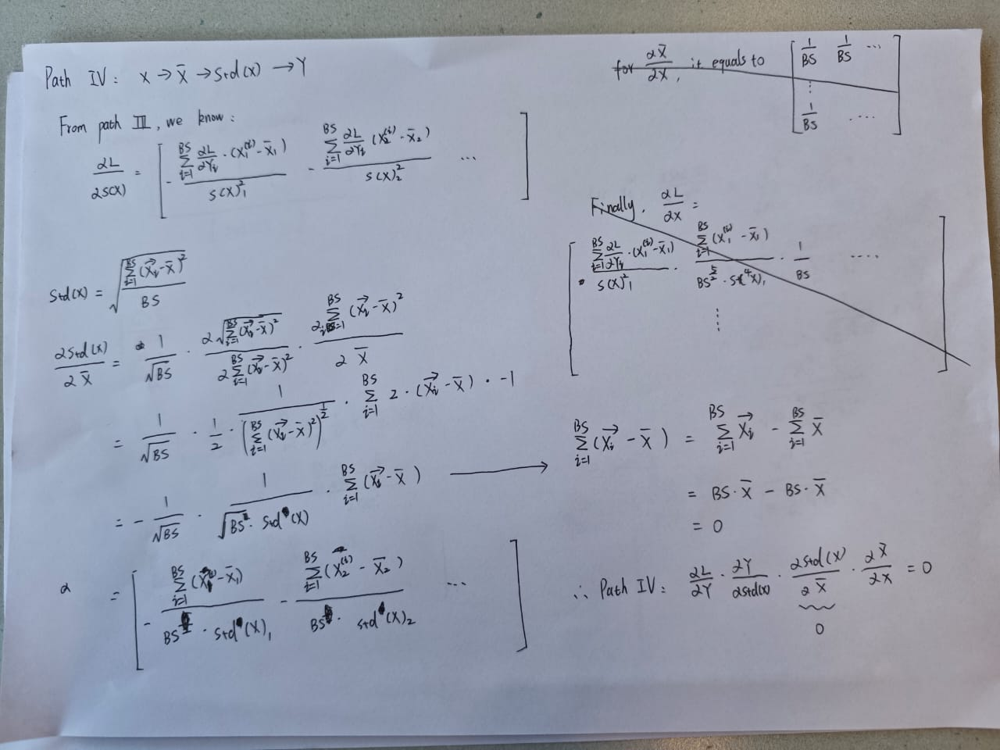

# Backpropagation of batchnormalization

This article talks about the backpropagation of batch normalization mathematically.

The formula of batch normalization is: xxx, where ...

Here is the data flow of batch normalization:

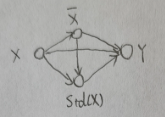

